# Exploratory Data Analysis of Spotify Tracks

**Consolidated project notebook — integration draft**  
Team size: 4 · Submission deadline: 25 November 2026

This is the single notebook intended to contain the whole project's analysis. It follows the flat, notebook-centered layout of the supplied reference repository. The official CSV and data dictionary sit beside this notebook. The raw data is never overwritten.

> **Integration status (23 November 2026):** dataset inspection, cleaning logic, leader recommendations evidence, and temporal analysis are included. Member 1's full univariate charts, Member 2's full bivariate section, Member 3's multivariate/outlier section, and the final subjective-answer PDF are still pending teammate results. Do not present this integration draft as finished until these sections are completed and reviewed.


## 1. Project objective and questions

Describe the supplied Spotify tracks dataset; profile its variables; examine relationships among audio features and popularity; compare selected groups; and study changes over release year. Recommendations must follow evidence. This observational dataset can show associations, not prove that a musical feature causes popularity.

The official problem statement has four analysis areas: **Univariate, Bivariate, Multivariate, and Time-series/Temporal**. It also requires a well-commented notebook, a PDF answering the subjective questions, and a README. The PDF remains a separate required deliverable; this notebook is the consolidated code and analysis file.


## 2. Team responsibilities and integration status

| Owner | Section | Status in this notebook |
|---|---|---|
| Leader | Data foundation, temporal analysis, recommendations, final integration | Temporal analysis and initial recommendation evidence included; broader temporal questions and final integration remain. |
| Member 1 | Data cleaning review and Univariate Analysis | **Pending:** add verified distributions, plots, interpretations, and sample sizes here. |
| Member 2 | Bivariate Analysis | **Pending:** add relationship plots and a coefficient table with valid sample sizes here. |
| Member 3 | Multivariate and Outlier Analysis | **Pending:** add defined group comparisons, multivariate graphs, outlier method, and inspected results here. |

Members may use temporary notebooks to work, but the final submitted project analysis must be integrated into this one notebook.


## 3. Libraries

Pandas reads and summarizes the table. NumPy is available for simple numeric work. Matplotlib and Seaborn make the graphs.

The shared module `src/spotify_chart_style.py` applies the Spotify Premium dark editorial theme (colours, fonts, gridlines, export quality) to every chart. Teammates can import the same module for their sections so all graphs look consistent.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.spotify_chart_style import (
    apply_spotify_style, spotify_green, muted_grey, muted_blue, muted_sand,
)

apply_spotify_style()


## 4. Load the supplied dataset

Run Jupyter from the project root so the notebook can read the CSV beside it. The file `spotify_tracks.csv` is copied from the dataset folder provided with the problem statement.


In [2]:
df = pd.read_csv('spotify_tracks.csv')
print(df.head())


                 track_id                                  track_name  \
0  2r0ROhr7pRN4MXDMT1fEmd                  Leo Das Entry (From "Leo")   
1  4I38e6Dg52a2o2a8i5Q5PW                                AAO KILLELLE   
2  59NoiRhnom3lTeRFaBzOev      Mayakiriye Sirikiriye - Orchestral EDM   
3  5uUqRQd385pvLxC8JX3tXn    Scene Ah Scene Ah - Experimental EDM Mix   
4  1KaBRg2xgNeCljmyxBH1mo  Gundellonaa X I Am A Disco Dancer - Mashup   

                                         artist_name  year  popularity  \
0                                Anirudh Ravichander  2024          59   
1  Anirudh Ravichander, Pravin Mani, Vaishali Sri...  2024          47   
2           Anirudh Ravichander, Anivee, Alvin Bruno  2024          35   
3  Anirudh Ravichander, Bharath Sankar, Kabilan, ...  2024          24   
4  Anirudh Ravichander, Benny Dayal, Leon James, ...  2024          22   

                                         artwork_url  \
0  https://i.scdn.co/image/ab67616d0000b273ce9c65...   
1  h

## 5. Inspect the data structure

Check row and column counts, column names, data types, blank values, duplicates, ID repeats, year range, and language categories before analysis.


In [3]:
print('Rows and columns:', df.shape)
print('Column names:', list(df.columns))
print('Data types:')
print(df.dtypes)
print('Blank cells:', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())
print('Duplicate track IDs:', df['track_id'].duplicated().sum())
print('Year range:', df['year'].min(), 'to', df['year'].max())
print('Language counts:')
print(df['language'].value_counts(dropna=False))


Rows and columns: (62317, 22)
Column names: ['track_id', 'track_name', 'artist_name', 'year', 'popularity', 'artwork_url', 'album_name', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'track_url', 'language']
Data types:
track_id                str
track_name              str
artist_name             str
year                  int64
popularity            int64
artwork_url             str
album_name              str
acousticness        float64
danceability        float64
duration_ms         float64
energy              float64
instrumentalness    float64
key                 float64
liveness            float64
loudness            float64
mode                float64
speechiness         float64
tempo               float64
time_signature      float64
valence             float64
track_url               str
language                str
dtype: object
Blank cells: 0
Exact duplic

### Numeric summary of the raw file

These values include the invalid extraction sentinels and duplicate rows. Use them to understand the source; use the processed copy for analysis.


In [4]:
print(df.describe().T)


                    count           mean            std       min  \
year              62317.0    2014.425935       9.645113    1971.0   
popularity        62317.0      15.358361      18.626908       0.0   
acousticness      62317.0       0.362292       0.314609      -1.0   
danceability      62317.0       0.596807       0.186209      -1.0   
duration_ms       62317.0  242527.040021  112999.932607    5000.0   
energy            62317.0       0.602496       0.246144      -1.0   
instrumentalness  62317.0       0.146215       0.307804      -1.0   
key               62317.0       5.101658       3.553469      -1.0   
liveness          62317.0       0.194143       0.172030      -1.0   
loudness          62317.0     -65.103433    2369.051478 -100000.0   
mode              62317.0       0.586052       0.493682      -1.0   
speechiness       62317.0       0.087722       0.115150      -1.0   
tempo             62317.0     117.931247      28.509459      -1.0   
time_signature    62317.0       3.

## 6. Data cleaning

The source contains 78 exact repeated rows. It also contains 35 records with -1 in 11 audio/code fields and -100,000 loudness in the same records. That shared pattern indicates failed feature extraction. We remove only exact duplicate rows and mark the 12 sentinel measurements missing. We do not impute values or delete those records. The raw CSV remains unchanged.

The supplied data dictionary and local source audit are available as `spotify_data_description.csv` and in `outputs/reports/REFERENCE_AUDIT.md`.


In [5]:
df_clean = df.drop_duplicates().copy()
sentinel_columns = [
    'acousticness', 'danceability', 'energy', 'instrumentalness',
    'key', 'liveness', 'mode', 'speechiness', 'tempo',
    'time_signature', 'valence'
]

for column in sentinel_columns:
    df_clean.loc[df_clean[column] == -1, column] = np.nan

df_clean.loc[df_clean['loudness'] <= -1000, 'loudness'] = np.nan

print('Processed shape:', df_clean.shape)
print('Missing cells after marking sentinels:', df_clean.isna().sum().sum())
print('Duplicate rows after cleaning:', df_clean.duplicated().sum())
print('Duplicate track IDs after cleaning:', df_clean['track_id'].duplicated().sum())

df_clean.to_csv('data/processed/cleaned_spotify_tracks.csv', index=False)


Processed shape: (62239, 22)
Missing cells after marking sentinels: 420


Duplicate rows after cleaning: 0
Duplicate track IDs after cleaning: 0


### Processed data profile

The code below summarizes the cleaned working table. Missing feature values are skipped by Pandas summary functions. URL and free-text fields are not inputs to numeric routines.


In [6]:
numeric_columns = df_clean.select_dtypes(include='number').columns
print(df_clean[numeric_columns].describe().T)


                    count           mean            std     min          25%  \
year              62239.0    2014.417969       9.648517  1971.0    2011.0000   
popularity        62239.0      15.357589      18.630494     0.0       0.0000   
acousticness      62204.0       0.363108       0.313098     0.0       0.0673   
danceability      62204.0       0.597667       0.182422     0.0       0.4980   
duration_ms       62239.0  242603.445557  113021.005225  5000.0  192240.0000   
energy            62204.0       0.603318       0.243324     0.0       0.4400   
instrumentalness  62204.0       0.146699       0.306520     0.0       0.0000   
key               62204.0       5.104977       3.551483     0.0       2.0000   
liveness          62204.0       0.194844       0.169775     0.0       0.0932   
loudness          62204.0      -8.945049       5.332863   -60.0     -10.7200   
mode              62204.0       0.586956       0.492385     0.0       0.0000   
speechiness       62204.0       0.088353

In [7]:
language_summary = df_clean.groupby('language').agg(
    track_count=('track_id', 'count'),
    average_popularity=('popularity', 'mean'),
    median_popularity=('popularity', 'median'),
    average_energy=('energy', 'mean')
).sort_values('track_count', ascending=False)
print(language_summary.round(2))


           track_count  average_popularity  median_popularity  average_energy
language                                                                     
English          23389               14.76                5.0            0.53
Unknown          13005               12.26                4.0            0.61
Tamil            12609               11.91                3.0            0.62
Korean            6893               27.55               26.0            0.76
Hindi             5740               18.20               11.0            0.65
Telugu             321               14.32                9.0            0.67
Malayalam          282                7.32                2.0            0.68


## 7. Univariate Analysis — Member 1

**Status: pending teammate handoff.** Add the finished, beginner-readable analysis in this section. Cover distributions and summary statistics for popularity, duration, key, tempo, acousticness, loudness, danceability, energy, time signature, speechiness, valence, instrumentalness, liveness, mode, and language.

Required discussion includes mean/median and quartiles where useful, frequency counts for categorical fields, plots with clear labels, and a note that a continuous variable such as energy needs defined bins before a mode is meaningful. Do not repeat the invalid -1 sentinels as real values.

**Insert Member 1's reviewed code cells, graphs, interpretations, and findings below.**


## 8. Bivariate Analysis — Member 2

**Status: pending teammate handoff.** Test the official question pairs: duration/popularity; danceability/popularity; energy/popularity; loudness/popularity; acousticness/popularity; valence/popularity; instrumentalness/popularity; liveness/popularity; tempo/popularity; language/popularity; key and mode/popularity; time_signature/popularity.

Use scatter plots for continuous pairs and grouped plots for categorical comparisons. Include the method, coefficient, direction, strength, and valid pair count. Pearson describes linear association; it does not prove causation.

Initial leader evidence for recommendation context (to cross-check, not a substitute for Member 2's section): energy/popularity r=0.147, danceability/popularity r=0.042, valence/popularity r=0.009, acousticness/popularity r=-0.138, and instrumentalness/popularity r=-0.127. These are weak correlations.

**Insert Member 2's reviewed code cells, graphs, interpretations, and findings below.**


## 9. Multivariate and Outlier Analysis — Member 3

**Status: pending teammate handoff.** Examine feature combinations, including danceability/energy/valence among the highest popularity quartile; acousticness/instrumentalness/speechiness; loudness/tempo/mode; language-specific audio features; joint key/mode/time_signature groups; and duration/liveness among high-popularity tracks by decade.

Define popularity groups and any clustering method. For outliers, state the rule, bounds, counts, and percentages, then inspect examples. An IQR flag is not automatically an error. Do not write “hit recipe” or causal conclusions from observational group averages.

**Insert Member 3's reviewed code cells, graphs, interpretations, and findings below.**


## 10. Temporal Analysis — Leader

This completed section groups the processed data by release year. Years with fewer than 30 tracks stay in the summary and count graph. In trend plots they appear as faint points and are not connected in the emphasized line. The 30-track cutoff is a visual aid, not a statistical test.


In [8]:
yearly_track_count = df_clean.groupby('year')['track_id'].count().sort_index()
print(yearly_track_count)


year
1971      12
1972      21
1973      62
1974      10
1975      19
1976       9
1977      39
1978      14
1979      46
1980      20
1981      37
1982     164
1983     176
1984     213
1985     256
1986     260
1987     210
1988     230
1989     297
1990     416
1991     268
1992     405
1993     366
1994     522
1995     457
1996     306
1997     412
1998     292
1999     296
2000     376
2001     493
2002     494
2003     594
2004     527
2005     854
2006     786
2007     865
2008     977
2009    1182
2010    1588
2011    1621
2012    1965
2013    3362
2014    2787
2015    2626
2016    2821
2017    2896
2018    2971
2019    2807
2020    3035
2021    3698
2022    5181
2023    6427
2024    5471
Name: track_id, dtype: int64


In [9]:
yearly_summary = df_clean.groupby('year').agg(
    track_count=('track_id', 'count'),
    average_popularity=('popularity', 'mean'),
    median_popularity=('popularity', 'median'),
    average_energy=('energy', 'mean'),
    average_danceability=('danceability', 'mean'),
    average_valence=('valence', 'mean')
).sort_index()
print(yearly_summary.head())


      track_count  average_popularity  median_popularity  average_energy  \
year                                                                       
1971           12           30.666667               31.0        0.332800   
1972           21           26.809524               24.0        0.585905   
1973           62           27.064516               22.5        0.568048   
1974           10           31.000000               30.5        0.565290   
1975           19           37.368421               37.0        0.678789   

      average_danceability  average_valence  
year                                         
1971              0.467250         0.397050  
1972              0.534714         0.722048  
1973              0.502290         0.533889  
1974              0.523000         0.502420  
1975              0.478421         0.597632  


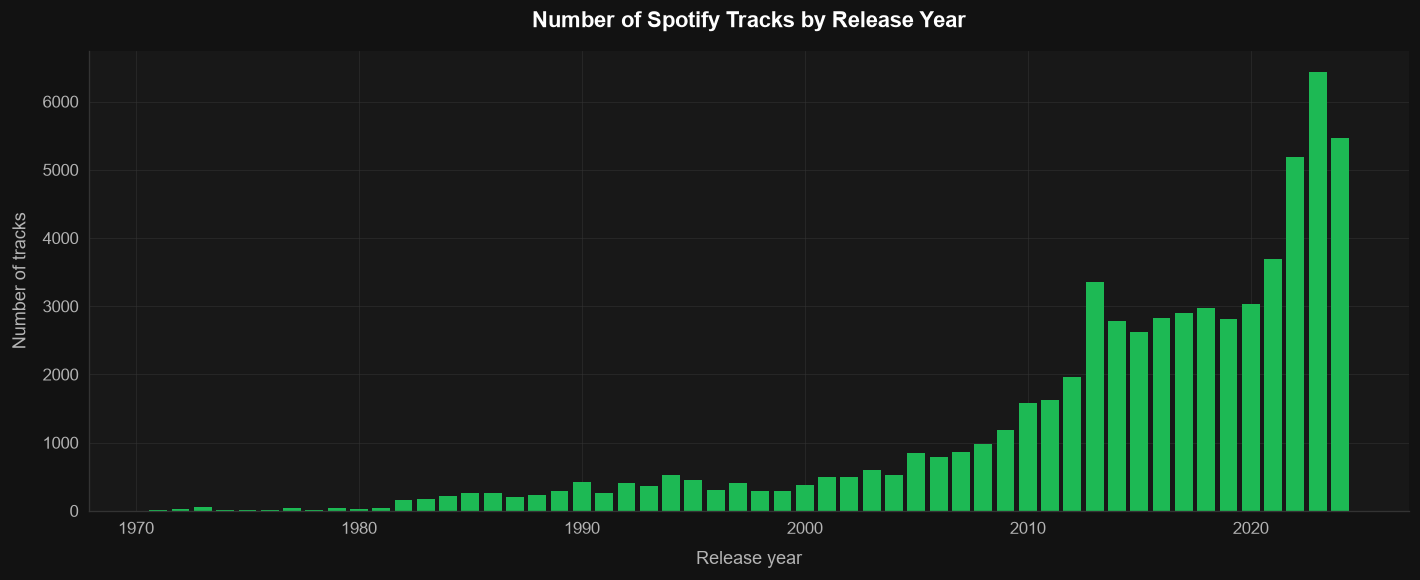

In [10]:
minimum_tracks = 30
reliable_years = yearly_track_count[yearly_track_count >= minimum_tracks].index

plt.figure(figsize=(12, 5))
plt.bar(yearly_track_count.index, yearly_track_count.values, color=spotify_green, edgecolor='none')
plt.title('Number of Spotify Tracks by Release Year')
plt.xlabel('Release year')
plt.ylabel('Number of tracks')
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_track_count.png', dpi=300)
plt.show(block=False)
plt.close()


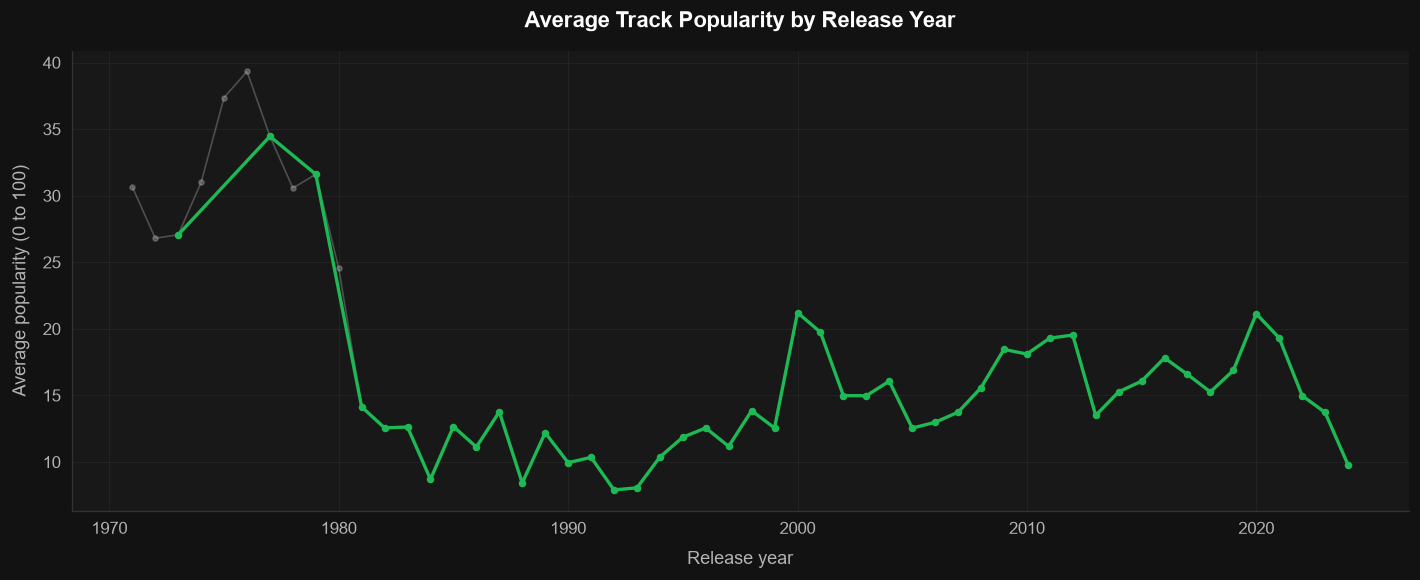

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_popularity'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_popularity'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Popularity by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average popularity (0 to 100)')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_popularity.png', dpi=300)
plt.show(block=False)
plt.close()


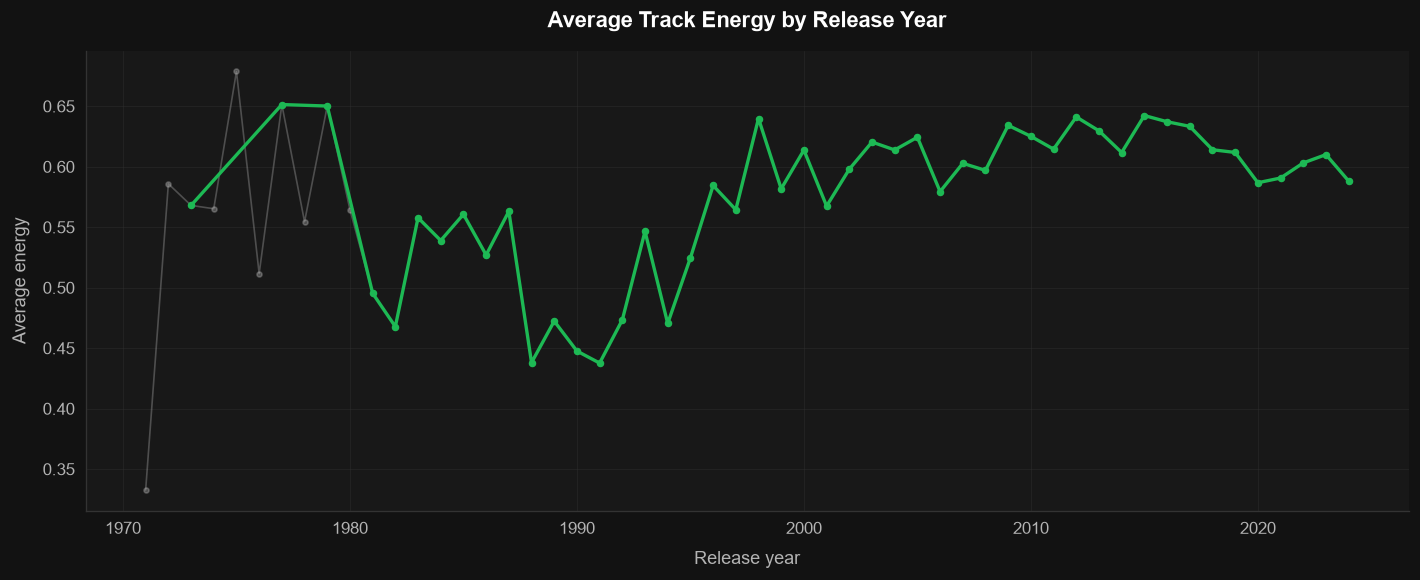

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_energy'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_energy'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Energy by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average energy')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_energy.png', dpi=300)
plt.show(block=False)
plt.close()


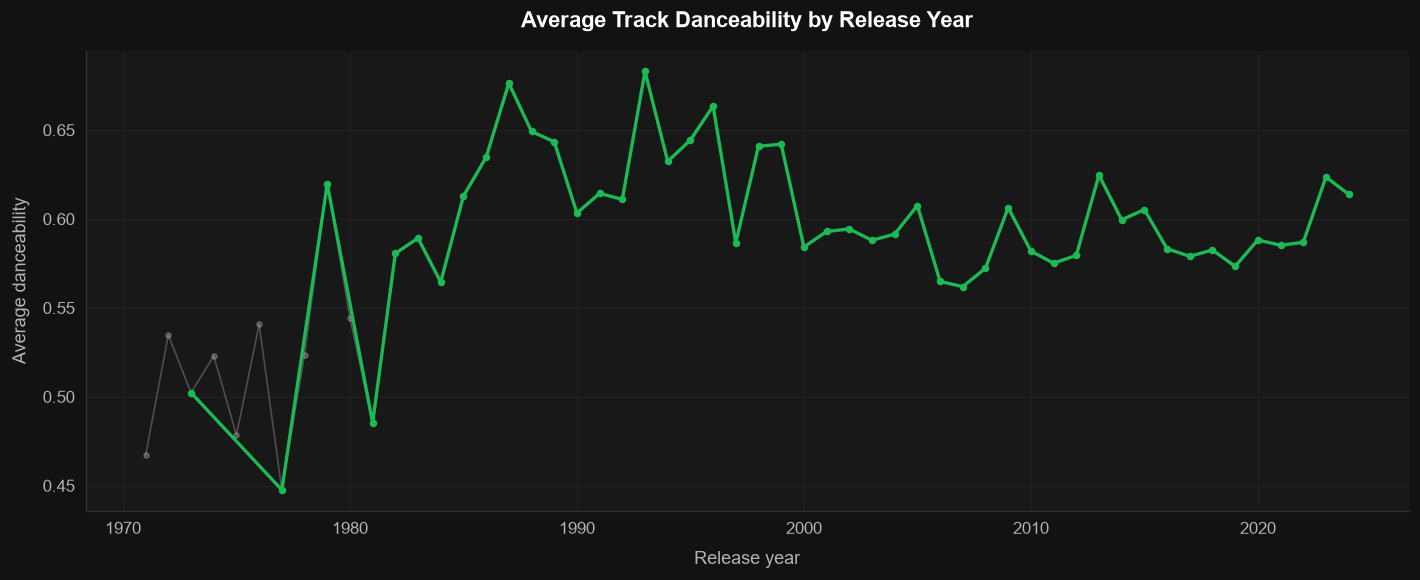

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_danceability'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_danceability'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Danceability by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average danceability')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_danceability.png', dpi=300)
plt.show(block=False)
plt.close()


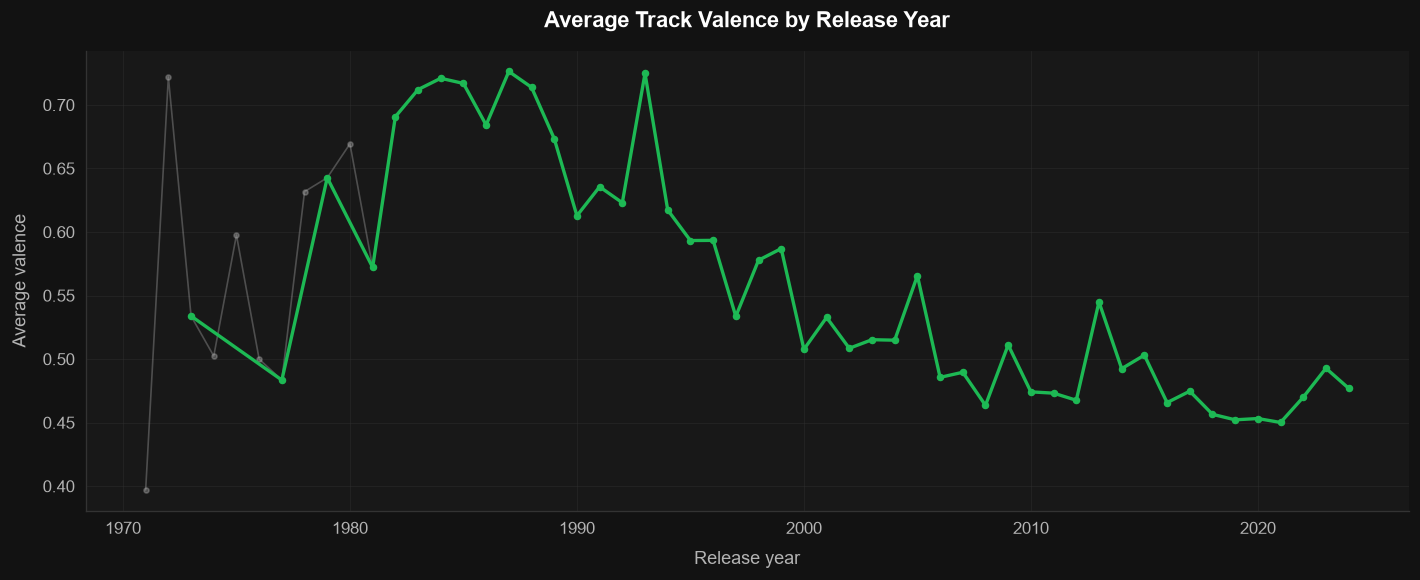

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_valence'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_valence'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Valence by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average valence')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_valence.png', dpi=300)
plt.show(block=False)
plt.close()


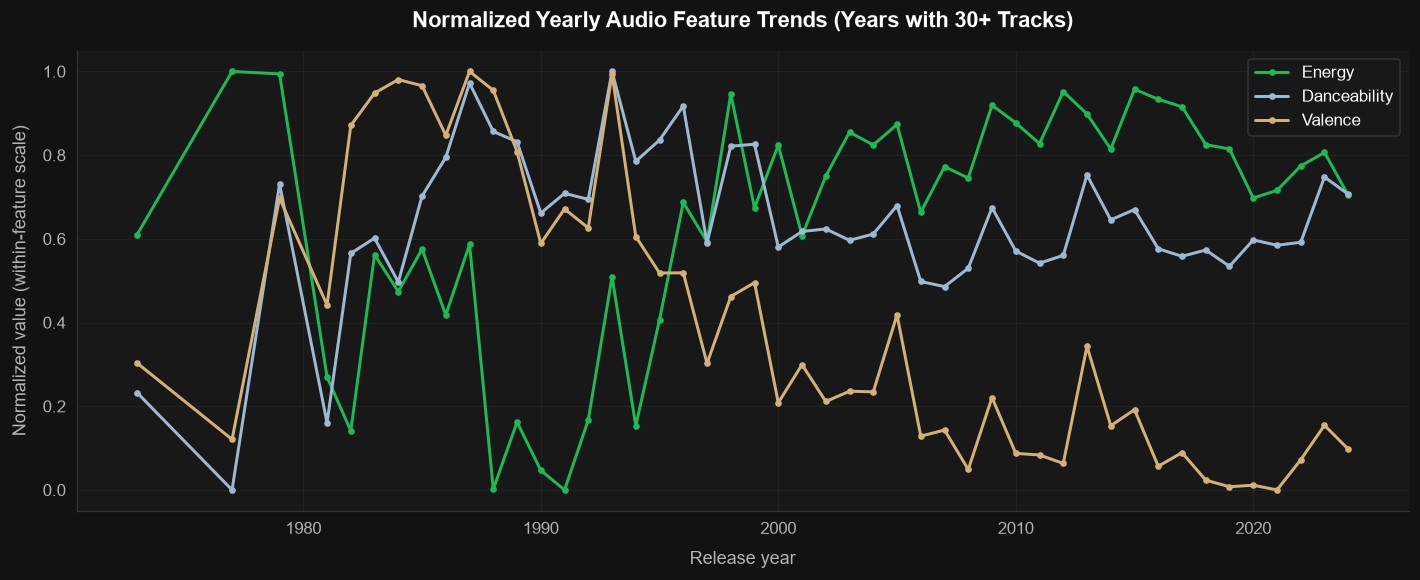

In [15]:
yearly_energy = df_clean.groupby('year')['energy'].mean().sort_index()
yearly_danceability = df_clean.groupby('year')['danceability'].mean().sort_index()
yearly_valence = df_clean.groupby('year')['valence'].mean().sort_index()

combined_features = pd.DataFrame({
    'Energy': yearly_energy,
    'Danceability': yearly_danceability,
    'Valence': yearly_valence
}).loc[reliable_years]

normalized_features = (combined_features - combined_features.min()) / (combined_features.max() - combined_features.min())

feature_colors = {'Energy': spotify_green, 'Danceability': muted_blue, 'Valence': muted_sand}

plt.figure(figsize=(12, 5))
for column in normalized_features.columns:
    plt.plot(normalized_features.index, normalized_features[column], color=feature_colors[column], marker='o', markersize=3, linewidth=1.8, label=column)
plt.title('Normalized Yearly Audio Feature Trends (Years with 30+ Tracks)')
plt.xlabel('Release year')
plt.ylabel('Normalized value (within-feature scale)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/combined_temporal_features.png', dpi=300)
plt.show(block=False)
plt.close()


In [16]:
print('Most represented year:', int(yearly_track_count.idxmax()), '-', int(yearly_track_count.max()), 'tracks')
print('Least represented year:', int(yearly_track_count.idxmin()), '-', int(yearly_track_count.min()), 'tracks')
print('Years with fewer than', minimum_tracks, 'tracks:', list(yearly_track_count[yearly_track_count < minimum_tracks].index))
print('Year with highest mean popularity:', int(yearly_summary['average_popularity'].idxmax()))
print('Year with lowest mean popularity:', int(yearly_summary['average_popularity'].idxmin()))


Most represented year: 2023 - 6427 tracks
Least represented year: 1976 - 9 tracks
Years with fewer than 30 tracks: [1971, 1972, 1974, 1975, 1976, 1978, 1980]
Year with highest mean popularity: 1976
Year with lowest mean popularity: 1992


### Temporal interpretation

The file spans 1971–2024. Track count is highest in 2023 (6,427) and lowest in 1976 (9). Mean popularity is highest in 1976 (39.33, n=9) and lowest in 1992 (7.90, n=405). Among years with at least 30 tracks, mean popularity is highest in 1977 (34.46, n=39) and lowest in 1992 (7.90, n=405). The small 1976 group makes its high average unstable.

For years with at least 30 tracks, mean energy ranges 0.438 (1991) to 0.651 (1977); danceability 0.448 (1977) to 0.683 (1993); valence 0.450 (2021) to 0.726 (1987). These are descriptive year-group averages. They do not prove that musical preferences changed for a particular reason.

The combined chart separately min-max normalizes energy, danceability, and valence. It compares broad within-feature shapes only. The y-values are not the original feature values; popularity is excluded because its scale differs.


### Additional official time-series questions — leader coordination

The problem statement also asks about duration, loudness, tempo, acousticness, instrumentalness, liveness, speechiness, language prevalence, key prevalence, and changing energy/danceability relationships over time. These are **not all answered yet** in this notebook. Add only after coordinating with teammates and defining “popular tracks” consistently (for example, popularity at or above the processed data's Q3=26, while noting ties). Include yearly sample counts. Popularity is a current score, not a score recorded at release.


## 11. Recommendations — evidence and limits

### Supported actions to consider

1. **Validate data on every refresh.** Check exact duplicates, sentinel values, missing language, and reasonable ranges before using summaries.
2. **Run creative tests instead of copying a formula.** The energy/popularity correlation is weak (r=0.147). Test alternative arrangements with a fair comparison and measurable audience outcomes.
3. **Research audience segments carefully.** Korean-tagged tracks have the highest language mean in this file (27.55; median 26; n=6,893), but group averages do not explain why. Compare multiple releases and include sample sizes.
4. **Use historical trends as context.** Pair release timing ideas with current audience data; year patterns are not forecasts.

Possible success measures for a future test include saves, completion rate, repeat listening, and campaign conversion. These measures are not present in this CSV, so do not claim measured business impact here.


In [17]:
print('Energy/popularity Pearson r:', df_clean['energy'].corr(df_clean['popularity']))
print('Danceability/popularity Pearson r:', df_clean['danceability'].corr(df_clean['popularity']))
print('Valence/popularity Pearson r:', df_clean['valence'].corr(df_clean['popularity']))
print('Acousticness/popularity Pearson r:', df_clean['acousticness'].corr(df_clean['popularity']))
print('Instrumentalness/popularity Pearson r:', df_clean['instrumentalness'].corr(df_clean['popularity']))
print('Energy/danceability Pearson r:', df_clean['energy'].corr(df_clean['danceability']))


Energy/popularity Pearson r: 0.14740280972028527
Danceability/popularity Pearson r: 0.042057824869718645
Valence/popularity Pearson r: 0.009150280465131388
Acousticness/popularity Pearson r: -0.1384326727423155
Instrumentalness/popularity Pearson r: -0.12714405972360177
Energy/danceability Pearson r: 0.46564902980639494


## 12. Limitations

- The dataset's language and year counts are uneven; the collection process is not fully documented.
- The popularity score is current and can reflect track age, promotion, artist reach, and platform exposure.
- The data have no listener-level demographics, listening histories, genre labels, or stream-event counts.
- Correlation and group averages are descriptive; no causal effect or future success is established.
- Member 1–3 sections and additional temporal questions must be integrated after review.


## 13. Conclusion

This dataset supports a careful description of track features and their observed relationships. Popularity is typically low (processed median 7), energy has only a weak positive correlation with popularity (r=0.147), and historical sample sizes vary widely. The responsible next step is to complete the teammate analyses, test recommendations with audience data, and avoid presenting a feature combination as a guaranteed hit formula.

### Source and project files

- Supplied data: `spotify_tracks.csv`
- Data dictionary: `spotify_data_description.csv`
- Reference audit: `outputs/reports/REFERENCE_AUDIT.md`
- Data profile: `outputs/reports/DATASET_PROFILE.md`
- Final project requirements and setup: `README.md`
